# Olist E-commerce Analysis: Data Cleaning and Exploration

**Goal:** prepare the Olist data for the Power BI dashboard and answer the delivery-related business questions.

**Business questions covered here:**
- How does delivery time (and lateness vs. the estimated date) affect review scores?
- What is the share of late deliveries?

**Output:** `data_clean/fact_sales.csv` (one row per order item), used by the dashboard.

## 1. Data loading
The five CSV files from the Kaggle Olist dataset are loaded with pandas: orders, order items, customers, reviews and products.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv("orders.csv")
items = pd.read_csv("order_items.csv")
customers = pd.read_csv("customers.csv")
reviews = pd.read_csv("order_reviews.csv")
products = pd.read_csv("products.csv")

## 2. Data quality audit
For each table: shape, data types, missing values and duplicated rows. Then specific checks on order status and on reviews.

In [8]:
for name, df in {"orders": orders, "items": items, "reviews": reviews, "products": products}.items():
    print(f"\n=== {name}: {df.shape} ===")
    print(df.dtypes)
    print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
    print("Fully duplicated rows:", df.duplicated().sum())

# Specific checks
print(orders["order_status"].value_counts())
print("Duplicate review_id:", reviews["review_id"].duplicated().sum())
print("Orders with multiple reviews:", reviews["order_id"].duplicated().sum())


=== orders: (99441, 8) ===
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object
Missing values:
 order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64
Fully duplicated rows: 0

=== items: (112650, 7) ===
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object
Missing values:
 Series([], dtype: int64)
Fully duplicated rows: 0

=== reviews: (99224, 7) ===
review_id                  object
order_id                   object
review_score                int64
review_comme

### Issues found and decisions

| Issue | What I found | Decision |
|---|---|---|
| Dates stored as text | All date columns are `object` type (5 in orders, plus shipping and review dates) | Converted with `pd.to_datetime` |
| Orders without a delivery date | 2,965 orders (canceled, unavailable, still in transit...) | Kept delivered orders with a delivery date only |
| Several reviews per order | 551 duplicated `order_id` in reviews (814 duplicated `review_id`) | Averaged the score per order, to avoid counting an order twice |
| Products without a category | 610 products | Labeled `unknown` |

## 3. Cleaning and feature engineering
- Date columns converted to datetime.
- Only **delivered** orders with a delivery date are kept.
- New columns: `delivery_days`, `delay_days`, `is_late`, `month`.
- `is_late` compares the two timestamps directly. Using whole days (`.dt.days`) would miss orders delivered a few hours after the estimated date.

In [9]:
date_cols = ["order_purchase_timestamp", "order_approved_at",
             "order_delivered_carrier_date", "order_delivered_customer_date",
             "order_estimated_delivery_date"]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

delivered = orders[orders["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]).copy()

delivered["delivery_days"] = (delivered["order_delivered_customer_date"]
                              - delivered["order_purchase_timestamp"]).dt.days
delivered["delay_days"] = (delivered["order_delivered_customer_date"]
                           - delivered["order_estimated_delivery_date"]).dt.days
delivered["is_late"] = (delivered["order_delivered_customer_date"]
                        > delivered["order_estimated_delivery_date"])
delivered["month"] = delivered["order_purchase_timestamp"].dt.to_period("M").astype(str)

# One review score per order (avoids double counting)
review_per_order = reviews.groupby("order_id", as_index=False)["review_score"].mean()
df = delivered.merge(review_per_order, on="order_id", how="left")

## 4. Outliers
Distribution of delivery time: the median is 10 days (mean 12.1) and the maximum is 209 days. The longest deliveries are real delivered orders, not data errors, so I kept them. The delay buckets used below are not distorted by a few extreme values.

count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_days, dtype: float64


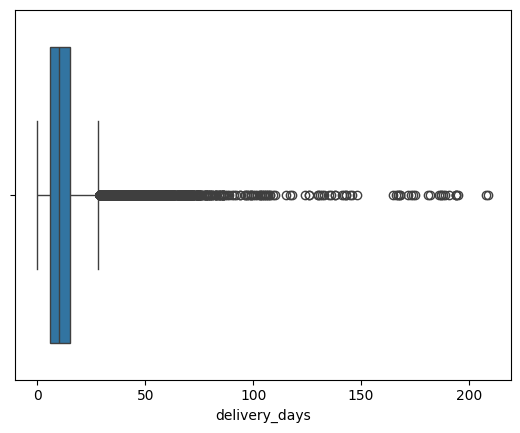

In [10]:
print(df["delivery_days"].describe())
sns.boxplot(x=df["delivery_days"]); plt.show()

## 5. Review score vs. lateness
Late orders average **2.57** vs **4.29** for on-time orders, a difference of about **40%**.
Note: this shows an association, not proof that lateness causes lower scores.

### Review score by delay bucket
Scores fall as the delay grows: 4.29 when early, 4.04 on the estimated day, 3.29 for 1-3 days late, 2.11 for 4-7 days late, and about 1.7 beyond one week. After about a week, satisfaction reaches its floor.

         mean  count
is_late             
False    4.29  88163
True     2.57   7661


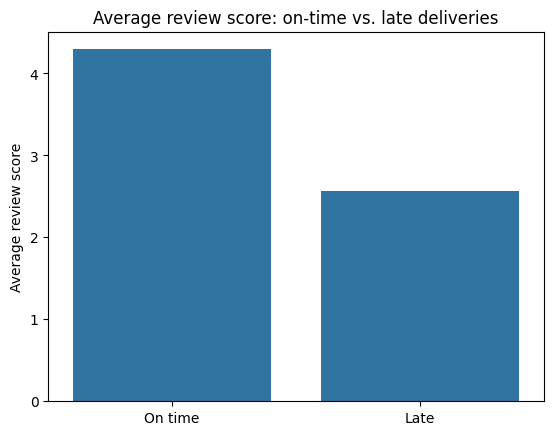

delay_bucket
Early            4.29
On day           4.04
1-3 days late    3.29
4-7 late         2.11
8-14 late        1.67
15+ late         1.73
Name: review_score, dtype: float64


In [11]:
# Review score by lateness
print(df.groupby("is_late")["review_score"].agg(["mean", "count"]).round(2))

sns.barplot(data=df, x="is_late", y="review_score", errorbar=None)
plt.xticks([0, 1], ["On time", "Late"])
plt.title("Average review score: on-time vs. late deliveries")
plt.xlabel(""); plt.ylabel("Average review score")
plt.show()

# Review score by delay bucket
df["delay_bucket"] = pd.cut(df["delay_days"], bins=[-100, -1, 0, 3, 7, 14, 200],
                            labels=["Early", "On day", "1-3 days late", "4-7 late", "8-14 late", "15+ late"])
print(df.groupby("delay_bucket", observed=True)["review_score"].mean().round(2))

## 6. Export for Power BI
One row per order item, with the customer's state and city, the product category, delivery metrics and the review score. Product categories missing in the data are labeled `unknown`.

In [12]:
import os
os.makedirs("data_clean", exist_ok=True)

# Main fact table: one row per order item, with everything needed for the dashboard
fact = (items.merge(df[["order_id", "customer_id", "month", "delivery_days",
                        "delay_days", "is_late", "review_score"]], on="order_id")
             .merge(customers[["customer_id", "customer_unique_id", "customer_state", "customer_city"]],
                    on="customer_id")
             .merge(products[["product_id", "product_category_name"]], on="product_id", how="left"))
fact["product_category_name"] = fact["product_category_name"].fillna("unknown")
fact.to_csv("data_clean/fact_sales.csv", index=False)

In [13]:
from google.colab import files
files.download("data_clean/fact_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Conclusions
- Late deliveries are associated with much lower review scores (about -40%).
- The score drops sharply after a short delay and stays at its minimum after about one week.
- **Limits:** association only, not causation; the dataset covers 2016-2018 from a single marketplace.